# Projeto de Aprendizado Não-Supervisionado: Análise de Doenças Cardíacas

**Base de referência:** Dissertação *"Heart Disease Analysis"* (CUNY Academic Works) — originalmente implementada em R e reproduzida/adaptada aqui em Python.
[https://academicworks.cuny.edu/gc_etds/5688/]

### Objetivo do Projeto
Investigar se algoritmos de **Aprendizado Não-Supervisionado** conseguem analisar exames médicos de pacientes (idade, pressão arterial, colesterol, dor no peito, frequência cardíaca, etc.) e **agrupar automaticamente pessoas com perfis clínicos parecidos**, sem que o modelo receba previamente o diagnóstico de quem possui ou não doença cardíaca.

## 1. Importação das Bibliotecas e Carregamento dos Dados
Nesta etapa, preparamos o ambiente Python com as ferramentas de manipulação de tabelas (`pandas`), gráficos (`matplotlib` e `seaborn`) e algoritmos de Machine Learning (`scikit-learn` e `scipy`). Em seguida, carregamos a base de dados clínica (`heart_disease.csv`) com os registros dos pacientes.

In [1]:
# Importação das bibliotecas essenciais para manipulação de dados, visualização e Machine Learning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)

# Carregamento do dataset extraído do repositório do artigo
df = pd.read_csv("heart_disease.csv")

print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.head())

Dimensões do dataset: 303 linhas e 14 colunas


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 2. Limpeza e Padronização dos Dados
Antes de aplicar qualquer algoritmo, precisamos tratar a base:
1. **Remoção de valores ausentes:** Eliminamos os poucos registros que possuem exames incompletos (`ca` e `thal`), seguindo o mesmo critério do artigo original.
2. **Separação do diagnóstico (`target`):** A coluna que indica a presença de doença cardíaca é guardada apenas para conferirmos o resultado no final. Ela **não** é usada no treinamento, garantindo que o aprendizado seja 100% não-supervisionado.
3. **Padronização (Z-score):** Como cada exame usa uma escala diferente (ex.: colesterol chega a 500, enquanto outros indicadores vão de 0 a 3), colocamos todas as variáveis na mesma régua para evitar que números maiores dominem o cálculo de distância.

In [2]:
# Verificação de valores ausentes (missing values)
print("Valores ausentes por coluna:")
print(df.isnull().sum())

# Remoção das 6 linhas com valores ausentes em 'ca' e 'thal' (mesmo procedimento do estudo)
df_clean = df.dropna().copy()

# Conversão das colunas 'ca' e 'thal' para inteiro após remoção dos nulos
df_clean["ca"] = df_clean["ca"].astype(int)
df_clean["thal"] = df_clean["thal"].astype(int)

# Criação da variável binária 'target' (0 = sem doença cardíaca, 1 = presença de doença cardíaca)
# Observação: 'target' NÃO será usada no treinamento dos algoritmos não-supervisionados,
# servindo apenas para avaliar clinicamente os clusters formados ao final.
df_clean["target"] = (df_clean["num"] > 0).astype(int)

# Separação das features (X) que serão usadas na análise não-supervisionada
features = ["age", "sex", "cp", "trestbps", "chol", "fbs",
            "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
X = df_clean[features]

# Padronização (Z-score): indispensável para PCA, K-Means e Clustering Hierárquico,
# pois variáveis como 'chol' (~250) têm escala muito maior que 'oldpeak' (~1.0).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print(f"\nDataset limpo: {df_clean.shape[0]} registros válidos.")
display(df_clean.describe().round(2))

Valores ausentes por coluna:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Dataset limpo: 297 registros válidos.


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
count,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00
mean,54.54,0.68,3.16,131.69,247.35,0.14,1.00,149.60,0.33,1.06,1.60,0.68,4.73,0.95,0.46
std,9.05,0.47,0.96,17.76,52.00,0.35,0.99,22.94,0.47,1.17,0.62,0.94,1.94,1.23,0.50
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.00,0.00,0.00,1.00,0.00,3.00,0.00,0.00
50%,56.00,1.00,3.00,130.00,243.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00,0.00
75%,61.00,1.00,4.00,140.00,276.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,2.00,1.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,4.00,1.00


## 3. Análise Exploratória (Correlação entre Exames)
Aqui visualizamos como cada exame se relaciona com os demais. Cores mais quentes (vermelho) indicam variáveis que sobem juntas; cores mais frias (azul) indicam relação inversa. Isso nos ajuda a entender quais sintomas clínicos caminham lado a lado.

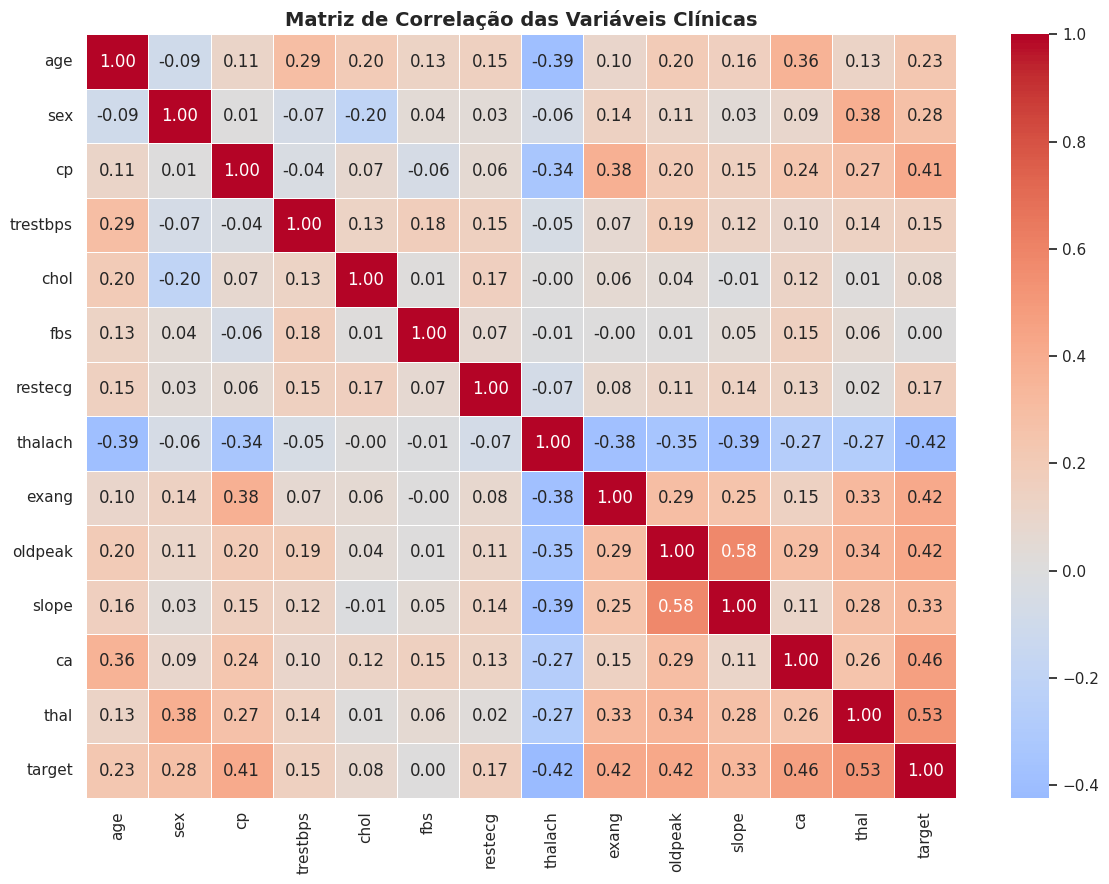

In [3]:
# Mapa de calor das correlações entre as variáveis clínicas
plt.figure(figsize=(12, 9))
corr_matrix = df_clean[features + ["target"]].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Matriz de Correlação das Variáveis Clínicas", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Redução de Dimensionalidade com PCA
Como é impossível desenhar um gráfico com 13 dimensões (uma para cada exame), utilizamos o **PCA (Análise de Componentes Principais)** para comprimir essas informações nos eixos principais (`PC1`, `PC2`, `PC3`) que concentram a maior parte da variação dos dados:
* **Scree Plot:** Mostra o percentual de informação preservado por cada componente.
* **Loadings (Pesos):** Indica quais exames tiveram maior influência na formação de cada componente.

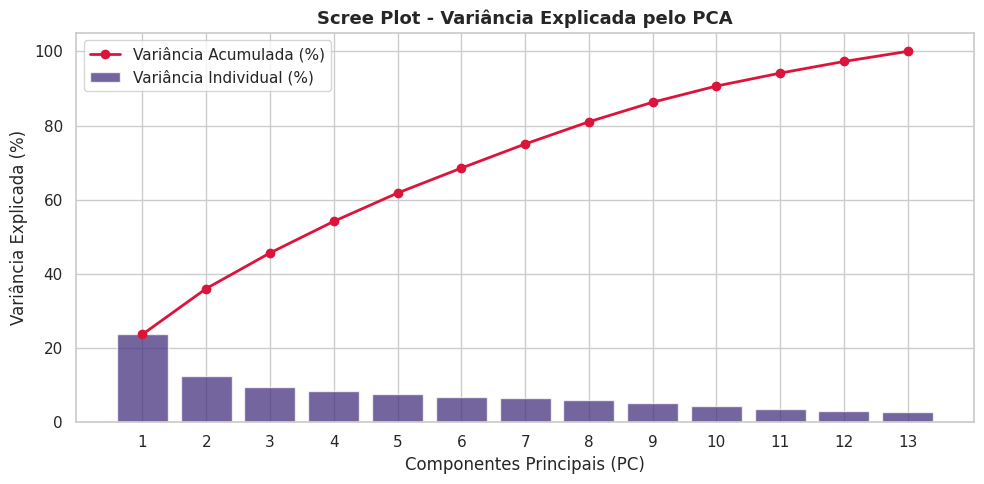

Loadings (contribuição das variáveis nos 3 primeiros componentes):


,PC1,PC2,PC3
age,0.286,-0.419,-0.013
sex,0.117,0.432,0.484
cp,0.286,0.153,-0.409
trestbps,0.168,-0.392,0.315
chol,0.084,-0.428,-0.260
fbs,0.076,-0.240,0.515
restecg,0.146,-0.267,0.072
thalach,-0.393,-0.054,0.219
exang,0.333,0.208,-0.197
oldpeak,0.397,0.062,0.045


In [4]:
# Aplicação do PCA mantendo todos os componentes inicialmente para analisar a variância explicada
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

# Scree Plot: Variância explicada por componente e acumulada
fig, ax = plt.subplots(figsize=(10, 5))
componentes = range(1, len(explained_var) + 1)

ax.bar(componentes, explained_var * 100, alpha=0.75, label="Variância Individual (%)")
ax.plot(componentes, cumulative_var * 100, marker="o", color="crimson", linewidth=2, label="Variância Acumulada (%)")
ax.set_xticks(componentes)
ax.set_xlabel("Componentes Principais (PC)")
ax.set_ylabel("Variância Explicada (%)")
ax.set_title("Scree Plot - Variância Explicada pelo PCA", fontsize=13, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

# Tabela de Loadings (pesos de cada variável nos 3 primeiros componentes)
loadings = pd.DataFrame(
    pca.components_[:3].T,
    columns=["PC1", "PC2", "PC3"],
    index=features
)
print("Loadings (contribuição das variáveis nos 3 primeiros componentes):")
display(loadings.round(3))

## 5. Agrupamento Hierárquico (Dendrogramas)
O **Clustering Hierárquico** funciona como uma árvore genealógica: ele começa juntando os pacientes com exames mais parecidos e vai unindo grupos vizinhos até formar grandes blocos. Reproduzimos os dois métodos testados no artigo (**Ward** e **Average Linkage**) para observar como os pacientes se dividem naturalmente em 2 grandes grupos.

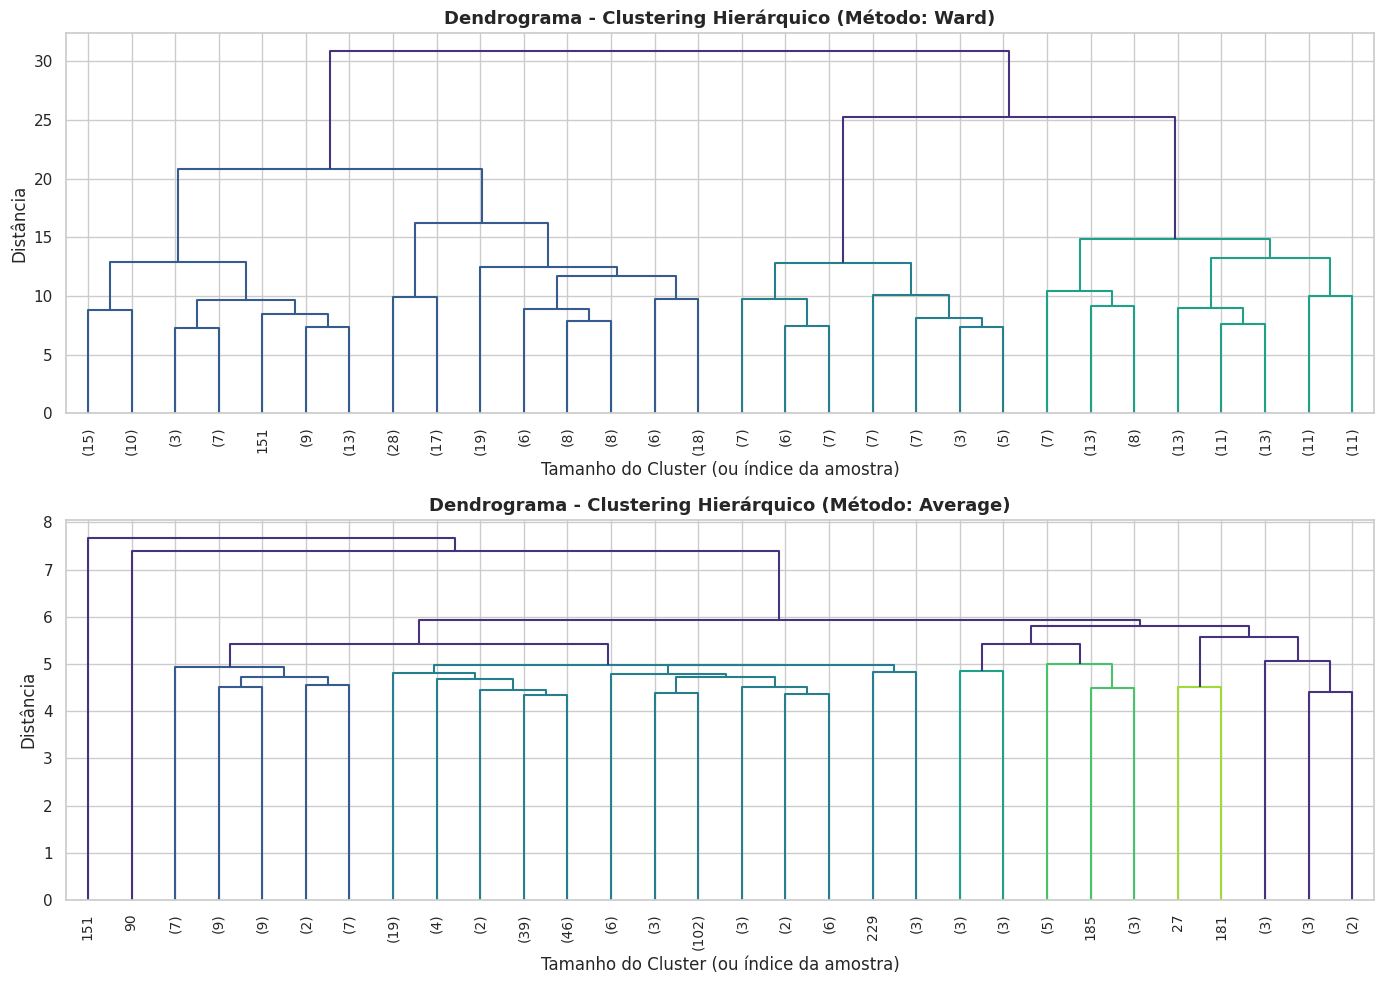

Distribuição dos pacientes nos clusters hierárquicos (Ward):
cluster_hc
1    168
0    129
Name: count, dtype: int64


In [5]:
# Comparação entre os métodos de ligação 'ward' e 'average' usados no artigo
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

for ax, method in zip(axes, ["ward", "average"]):
    Z = linkage(X_scaled, method=method)
    dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90., leaf_font_size=10., ax=ax)
    ax.set_title(f"Dendrograma - Clustering Hierárquico (Método: {method.capitalize()})", fontsize=13, fontweight="bold")
    ax.set_xlabel("Tamanho do Cluster (ou índice da amostra)")
    ax.set_ylabel("Distância")

plt.tight_layout()
plt.show()

# Aplicação do Clustering Hierárquico (Ward) com k=2 clusters
hc_ward = AgglomerativeClustering(n_clusters=2, linkage="ward")
df_clean["cluster_hc"] = hc_ward.fit_predict(X_scaled)

print("Distribuição dos pacientes nos clusters hierárquicos (Ward):")
print(df_clean["cluster_hc"].value_counts())

## 6. Definição do Número Ideal de Grupos (Cotovelo e Silhueta)
Para confirmar matematicamente qual a melhor quantidade de grupos ($k$) para dividir os pacientes, aplicamos duas métricas:
* **Método do Cotovelo (Inércia):** Mede o quão compactos os grupos ficam conforme aumentamos $k$.
* **Coeficiente de Silhueta:** Avalia o quão bem separados os grupos estão entre si (quanto maior o valor, mais nítida é a separação entre os perfis).

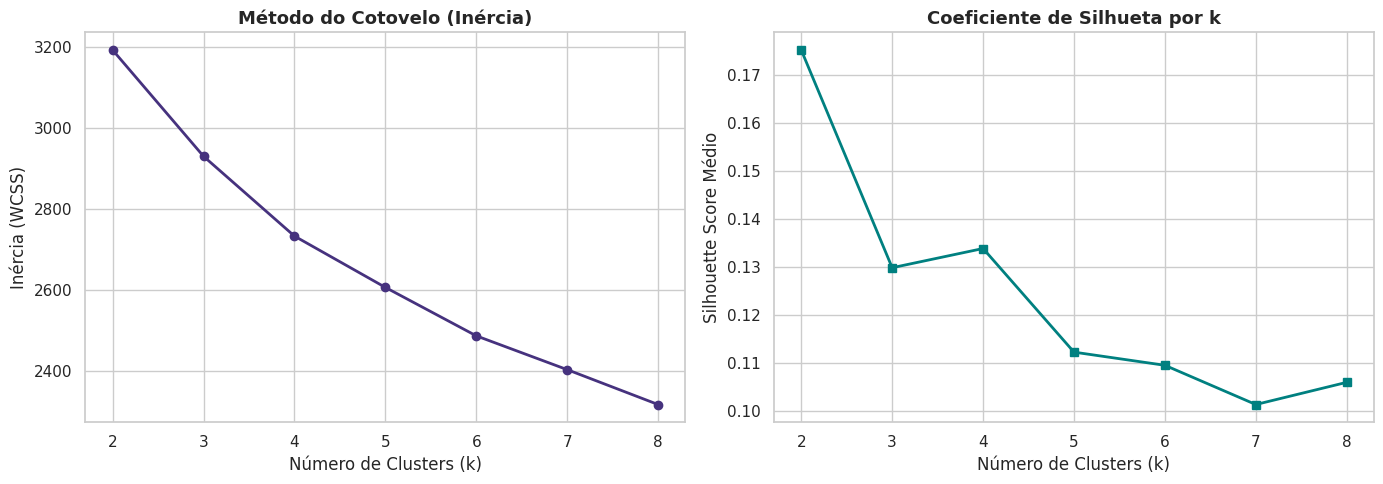

k = 2 -> Silhouette Score: 0.1751
k = 3 -> Silhouette Score: 0.1298
k = 4 -> Silhouette Score: 0.1338
k = 5 -> Silhouette Score: 0.1122
k = 6 -> Silhouette Score: 0.1095
k = 7 -> Silhouette Score: 0.1013
k = 8 -> Silhouette Score: 0.1060


In [6]:
# Avaliação de K de 2 a 8 usando Inércia (Elbow Method) e Coeficiente de Silhueta
k_range = range(2, 9)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico do Cotovelo (Elbow)
axes[0].plot(k_range, inertias, marker="o", linewidth=2)
axes[0].set_title("Método do Cotovelo (Inércia)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Número de Clusters (k)")
axes[0].set_ylabel("Inércia (WCSS)")

# Gráfico da Silhueta
axes[1].plot(k_range, silhouettes, marker="s", color="teal", linewidth=2)
axes[1].set_title("Coeficiente de Silhueta por k", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Número de Clusters (k)")
axes[1].set_ylabel("Silhouette Score Médio")

plt.tight_layout()
plt.show()

for k, sil in zip(k_range, silhouettes):
    print(f"k = {k} -> Silhouette Score: {sil:.4f}")

## 7. Algoritmo K-Means: Comparação entre Rodada 1 e Rodada 2
O algoritmo **K-Means** divide os pacientes em $k=2$ grupos buscando o centro mais representativo de cada perfil. Reproduzimos as duas rodadas propostas no estudo:
* **Rodada 1 (Todas as 13 variáveis):** Usa todos os exames disponíveis, inclusive aqueles que trazem ruído e pouco ajudam na separação.
* **Rodada 2 (Seleção das 7 variáveis mais relevantes):** Mantém apenas os exames clínicos mais decisivos (`cp`, `thalach`, `exang`, `oldpeak`, `slope`, `ca`, `thal`), elevando a qualidade e a nitidez do agrupamento.

Silhouette Score - Rodada 1 (todas as variáveis): 0.1751
Silhouette Score - Rodada 2 (variáveis selecionadas): 0.2904


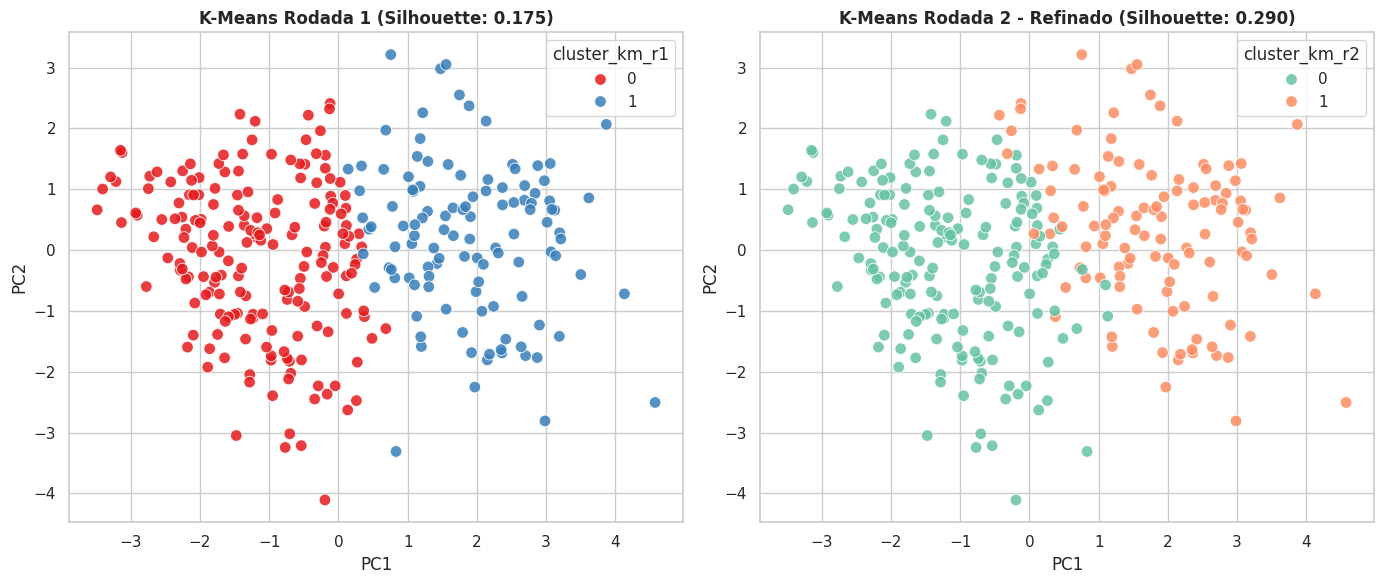

In [7]:
# --- RODADA 1: K-Means com todas as 13 variáveis ---
kmeans_r1 = KMeans(n_clusters=2, random_state=42, n_init=20)
df_clean["cluster_km_r1"] = kmeans_r1.fit_predict(X_scaled)
sil_r1 = silhouette_score(X_scaled, df_clean["cluster_km_r1"])

# --- RODADA 2 (Melhoria/Refinamento do artigo): K-Means com variáveis de maior peso no PCA/correlação ---
selected_features = ["cp", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
X_selected_scaled = scaler.fit_transform(df_clean[selected_features])

kmeans_r2 = KMeans(n_clusters=2, random_state=42, n_init=20)
df_clean["cluster_km_r2"] = kmeans_r2.fit_predict(X_selected_scaled)
sil_r2 = silhouette_score(X_selected_scaled, df_clean["cluster_km_r2"])

print(f"Silhouette Score - Rodada 1 (todas as variáveis): {sil_r1:.4f}")
print(f"Silhouette Score - Rodada 2 (variáveis selecionadas): {sil_r2:.4f}")

# Visualização dos Clusters no espaço dos 2 primeiros Componentes Principais (PCA)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=df_clean["cluster_km_r1"], palette="Set1", s=70, alpha=0.85, ax=axes[0]
)
axes[0].set_title(f"K-Means Rodada 1 (Silhouette: {sil_r1:.3f})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=df_clean["cluster_km_r2"], palette="Set2", s=70, alpha=0.85, ax=axes[1]
)
axes[1].set_title(f"K-Means Rodada 2 - Refinado (Silhouette: {sil_r2:.3f})", fontsize=12, fontweight="bold")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

## 8. Interpretação dos Grupos e Validação Final
Por fim, analisamos a média dos exames em cada grupo formado pelo **K-Means (Rodada 2)** e comparamos o resultado com o diagnóstico real que havia sido separado no início:
* Um dos grupos concentra pacientes mais jovens, com maior frequência cardíaca máxima e baixa incidência de dor no peito induzida por exercício (**perfil de baixo risco**).
* O outro grupo reúne pacientes com maior incidência de dor torácica, alterações no eletrocardiograma e vasos obstruídos (**perfil de alto risco cardíaco**).

Isso demonstra que o aprendizado não-supervisionado conseguiu identificar padrões clínicos reais de risco cardiovascular sem ter acesso prévio aos diagnósticos.

In [8]:
# Perfil médio de cada cluster na Rodada 2
print("Média das variáveis por cluster (K-Means Rodada 2):")
display(df_clean.groupby("cluster_km_r2")[features + ["target"]].mean().round(2))

# Tabela cruzada comparando os clusters não-supervisionados com o diagnóstico real ('target')
ct = pd.crosstab(
    df_clean["cluster_km_r2"],
    df_clean["target"],
    rownames=["Cluster (Não-Supervisionado)"],
    colnames=["Doença Cardíaca Real (0=Não, 1=Sim)"]
)
print("\nTabela de Contingência (Clusters vs. Diagnóstico Real):")
display(ct)

# Cálculo de concordância (pureza dos clusters)
acertos = max(ct.iloc[0, 0] + ct.iloc[1, 1], ct.iloc[0, 1] + ct.iloc[1, 0])
concordancia = acertos / len(df_clean) * 100
print(f"\nConcordância entre os agrupamentos não-supervisionados e o diagnóstico clínico: {concordancia:.2f}%")

Média das variáveis por cluster (K-Means Rodada 2):


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
cluster_km_r2,,,,,,,,,,,,,,
0,52.79,0.6,2.77,130.06,244.99,0.13,0.92,159.95,0.08,0.55,1.37,0.33,3.89,0.19
1,57.32,0.8,3.77,134.28,251.09,0.17,1.12,133.23,0.72,1.85,1.97,1.23,6.06,0.89



Tabela de Contingência (Clusters vs. Diagnóstico Real):


"Doença Cardíaca Real (0=Não, 1=Sim)",0,1
Cluster (Não-Supervisionado),,
0,147,35
1,13,102



Concordância entre os agrupamentos não-supervisionados e o diagnóstico clínico: 83.84%
